<a href="https://colab.research.google.com/github/Yiting-Wang98/MSSP607/blob/main/Modules/week11/week%2011%20assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'Yiting-Wang98'
repository = 'MSSP607'
repo_url = f'https://github.com/Yiting-Wang98/MSSP607.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP607
Files in repository:
Adding_File_Structure.py
Modules/week 10/week 10 assignment.ipynb
Modules/week 4/week 4module
Modules/week 6/week assignments6.ipynb
Modules/week 7/assignment_7.ipynb
Modules/week 8/week 8 assignment.ipynb
Modules/week 9/Week 09 Web Data.ipynb
Modules/week 9/week 9 photo/photos
Modules/week 9/week9 assignment.ipynb
Modules/week1/Participation_Activity_Week1_Exercises.ipynb
Modules/week1/Week 1 Introduction_To_Data_Analysis (2).ipynb
Modules/week1/stats_viz.py
Modules/week11/CA_Legislative_Districts.csv
Modules/week11/california-congressional-districts.geojson
Modules/week11/data
Modules/week11/klas12b-net-1.gexf
Modules/week2/Week 2 Data Stuctures.ipynb
Modules/week3/Week 3 Built In Data Structures Functions and Files.ipynb
Modules/week5/week5 module
assignment template.ipynb
assignments/case study report assignment 1/assignment 1.ipynb
assignments/case study report assignment 1

In [3]:
import geopandas as gp
import matplotlib.pyplot as plt

In [4]:
geo_files = list(Path('/content').rglob('california-congressional-districts*.geojson'))
csv_files = list(Path('/content').rglob('CA_Legislative_Districts*.csv'))

if not geo_files or not csv_files:
    raise FileNotFoundError('Please upload both original GeoJSON and CSV files to Colab and rerun this cell.')

pf = gp.read_file(str(geo_files[0]))
print('GeoJSON file:', geo_files[0])
print('CSV file:', csv_files[0])

GeoJSON file: /content/MSSP607/Modules/week11/california-congressional-districts.geojson
CSV file: /content/MSSP607/Modules/week11/CA_Legislative_Districts.csv


In [5]:

pf.head()

,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


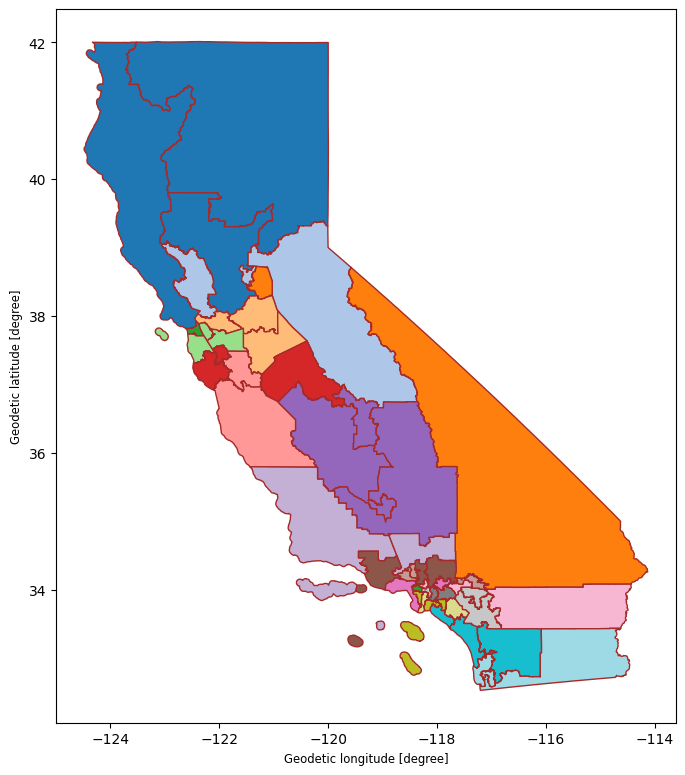

In [14]:

pf.plot(figsize=(8,10), cmap='tab20', edgecolor='brown', legend=True)
plt.show()

In [7]:

leg = gp.read_file(str(csv_files[0]))
print(leg.columns.tolist())
leg.head()

['OBJECTID', 'ID', 'AREA', 'DISTRICT', 'MEMBERS', 'NAME', 'POPULATION', 'CVAP_19', 'HSP_CVAP_1', 'DOJ_NH_BLK', 'DOJ_NH_ASN', 'NH_WHT_CVA', 'IDEAL_VALU', 'DEVIATION', 'F_DEVIATIO', 'MULTIPLE_F', 'F_CVAP_19', 'F_HSP_CVAP', 'F_DOJ_NH_B', 'F_DOJ_NH_A', 'F_NH_WHT_C', 'DISTRICT_L', 'DISTRICT_N', 'SHAPE_Length', 'SHAPE_Area']


,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,01,1,MTCAP,760066,549203,77031,10923,...,1|0,0.7226,0.1403,0.0199,0.0475,0.7507,1|0%,1,2633905.96774687,122295210592.513
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.6621,0.1335,0.0523,0.1713,0.622,10|0%,10,358288.980600586,2336909010.62173
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.7479,0.1076,0.0596,0.316,0.5006,11|0%,11,211193.171507614,940405406.889039
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.6723,0.1449,0.1994,0.2139,0.4169,12|-0%,12,124678.584690132,586947590.582839
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.5176,0.5024,0.0408,0.0621,0.3708,13|-0%,13,1186867.64961021,25781145591.7344


District boundaries kept: 53
Districts with no population: 1


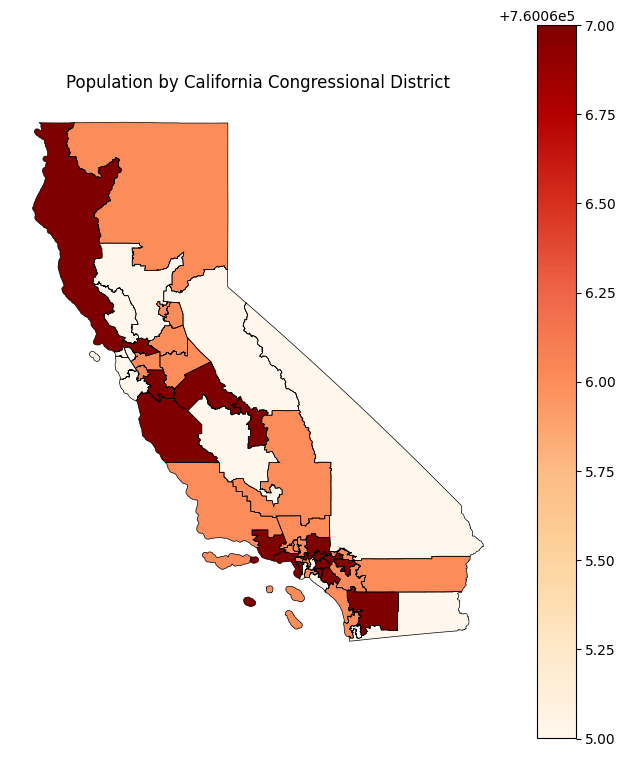

In [8]:

leg['DISTRICT'] = leg['DISTRICT'].astype(str).str.zfill(2)
merged = pf.merge(leg, left_on='Name', right_on='DISTRICT', how='left')


merged['POPULATION'] = (merged['POPULATION'].astype(str)
                        .str.replace(',', '', regex=False)
                        .astype(float))

print('District boundaries kept:', len(merged))
print('Districts with no population:', merged['POPULATION'].isna().sum())

ax = merged.plot(column='POPULATION', cmap='OrRd', legend=True, figsize=(8, 10))
pf.boundary.plot(ax=ax, edgecolor='black', linewidth=0.5)
plt.title('Population by California Congressional District')
plt.axis('off')
plt.show()

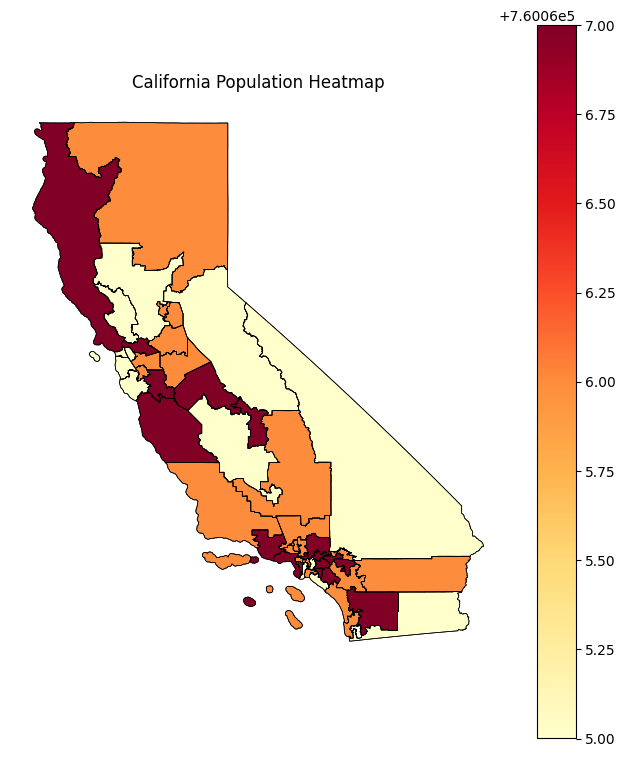

In [9]:

fig, ax = plt.subplots(figsize=(8, 10))
merged.plot(column='POPULATION', cmap='YlOrRd', legend=True,
            edgecolor='black', linewidth=0.5, ax=ax)
pf.boundary.plot(ax=ax, edgecolor='black', linewidth=0.5)
ax.set_title('California Population Heatmap')
ax.axis('off')
plt.show()